In [167]:
#Import libraries and define Symbols
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, RK45, BDF
from scipy.optimize import direct, Bounds
import time
from control import lqr

#Symbols
x, y, z, dx, dy, dz, phi, theta, psi, m, gx, gy, T, P, alpha, S, Cl, Cd, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, dphi, dtheta, dpsi = smp.symbols(
'x y z \\dot{x} \\dot{y} \\dot{z} phi theta psi m gamma_x gamma_y T P alpha S C_L C_D I_{xx} I_{yy} I_{zz} \\dot{I_{xx}}, \\dot{I_{yy}}, \\dot{I_{zz}} \\dot{\\phi}, \\dot{\\theta}, \\dot{\\psi}', cls=smp.Function)
t, g, rho, dCoP, dNoz = smp.symbols('t g rho d_{CoP} d_{Noz}')

In [168]:
#Forces, Moments, and State

#Rotation Matrices
def Rx(phi):
    return  smp.Matrix([[1,             0,              0],
                        [0, smp.cos(phi), -smp.sin(phi)],
                        [0, smp.sin(phi),  smp.cos(phi)]])
def Ry(theta):
    return  smp.Matrix([[ smp.cos(theta), 0,  smp.sin(theta)],
                        [             0, 1,              0],
                        [-smp.sin(theta), 0,  smp.cos(theta)]])
def Rz(psi):
    return  smp.Matrix([[smp.cos(psi), -smp.sin(psi), 0],
                        [smp.sin(psi),  smp.cos(psi), 0],
                        [0,             0,              1]])
Rbe = Rz(psi(t))*Ry(theta(t))*Rx(phi(t))
Reb=Rbe.T



#Forces

#Gravity
zHat = smp.Matrix([0,0,1])
Fg = -m(t)*g*zHat

#Thrust
FtHat = Rbe*Ry(gy(t))*Rx(gx(t))*zHat
Ft = FtHat*T(t)*(1-P(t))

#Lift (Approximately zero)
v = smp.Matrix([dx(t), dy(t), dz(t)])
Fl=smp.zeros(3,1)
'''#Actual Expression
LHat = (v.cross(Rbe*zHat)).cross(v)/ (v.dot(v)*smp.sin(alpha(t)))
L = smp.Rational(1/2)*rho*v.dot(v)*S(alpha(t))*Cl(alpha(t))
Fl = LHat * L
'''

#Drag
D = -smp.Rational(1/2)*rho*v.dot(v)*S(alpha(t))*Cd(alpha(t))
DHat = v / smp.sqrt(v.dot(v))
Fd = DHat*D

#Total force
F = Fg + Ft + Fl + Fd

#Acceleration
a = F / m(t)
a.simplify()



#Moment equations

#Body to Euler rate matrix
J = smp.Matrix([[1, smp.sin(phi(t))*smp.tan(theta(t)), smp.cos(phi(t))*smp.tan(theta(t))],
                [0,smp.cos(phi(t)), -smp.sin(phi(t))],
                [0, smp.sin(phi(t)) / smp.cos(theta(t)), smp.cos(phi(t)) / smp.cos(theta(t))]])


#Angular rates
av = smp.Matrix([dphi(t), dtheta(t), dpsi(t)])
omega = J.inv()* av
omega.simplify()

#Inertia matrix and rate
I = smp.diag(Ixx(t),Iyy(t),Izz(t))
dI = smp.diag(dIxx(t),dIyy(t),dIzz(t))

#Total moment (body)
M = (-dNoz*zHat).cross(Reb*Ft) + (-dCoP*zHat).cross(Reb*(Fl+Fd))
M.simplify()

#Angular acceleration (aa = [ddphi, ddtheta, ddpsi])
aa = J * I.inv() * (M - dI * omega - omega.cross(I * omega)) + J.diff(t).subs([(phi(t).diff(t),dphi(t)), (theta(t).diff(t),dtheta(t)), (psi(t).diff(t),dpsi(t))]) * omega
aa.simplify()


#Total state Equation
State = smp.Matrix([v, a, av, aa])


#Sub in simpler expressions for functions and variables
Statesub = State.subs([(dx(t), smp.Symbol('dx')), (dy(t), smp.Symbol('dy')), (dz(t), smp.Symbol('dz')), 
                    (phi(t), smp.Symbol('phi')), (theta(t), smp.Symbol('theta')), (psi(t), smp.Symbol('psi')), 
                    (dphi(t), smp.Symbol('dphi')), (dtheta(t), smp.Symbol('dtheta')), (dpsi(t), smp.Symbol('dpsi')), 
                    (gx(t), smp.Symbol('gx')), (gy(t), smp.Symbol('gy')), (P(t), smp.Symbol('P')), 
                    (Cd(alpha(t)), smp.Symbol('Cd')), (Cl(alpha(t)), smp.Symbol('Cl')), (S(alpha(t)), smp.Symbol('S')), 
                    (Ixx(t), smp.Symbol('Ixx')), (Iyy(t), smp.Symbol('Iyy')), (Izz(t), smp.Symbol('Izz')), 
                    (dIxx(t), smp.Symbol('dIxx')), (dIyy(t), smp.Symbol('dIyy')), (dIzz(t), smp.Symbol('dIzz')),
                    (T(t), smp.Symbol('T')), (m(t), smp.Symbol('m')), (dCoP, smp.Symbol('dCoP')), (dNoz, smp.Symbol('dNoz')) ])


#Convert state to numpy array
Statenp = smp.matrix2numpy(Statesub)


#Define Equations as functions
f_ddx = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'), 
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[3,0],'numpy')
f_ddy = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[4,0],'numpy')
f_ddz = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[5,0],'numpy')
f_ddphi = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[9,0],'numpy')
f_ddtheta = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[10,0],'numpy')
f_ddpsi = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[11,0],'numpy')

#Display state equation vector, [dx, dy, dz, ddx, ddy, ddz, dphi, dtheta, dpsi, ddphi, ddtheta, ddpsi] 
State

Matrix([
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [169]:
#Define linearized control matrices
def A(t, dz):
    a = np.zeros([4,4])
    a[0,1] = 1
    a[1,1] = -(rho*S*Cd)/(2*m) * np.abs(dz)
    a[1,2] = -T/m
    a[2,3] = 1
    a[3,1] =  (rho*S*Cd*dCoP)/(2*Iyy) * np.abs(dz)
    a[3,2] = (-(rho*S*Cd*dCoP)/(2*Iyy) * np.abs(dz) * dz)
    return a

def B(t, dz):
    b = np.zeros([4,2])
    b[1,0] = -T/m
    b[3,0] =  dNoz*T/Iyy
    return b

In [ ]:
#DiffEq Solver (BDF)

#Parameters
Cd = 0.1
Cl = 0.01
S = 0.01

Ixx = 0.2705
Iyy = 0.2705
Izz = 0.0124

dIxx = 0
dIyy = 0
dIzz = 0

T = 100
m = 7
g = 9.8
dCoP = 0.5
dNoz = 0.7
rho = 1.225

Q = np.diag([100,10,1000,1000])
R = np.diag([0.001,1])

# Define the system of ODEs
def system(t, State):
    x, y, z, dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi = State

    #LQR to find K
    At = A(t, dz)
    Bt = B(t, dz)
    K, Ric, Eig = lqr(At, Bt, Q, R)

    #Set control parameters
    gy, P = -K @ [x, dx, -theta, -dtheta]
    gx, P = -K @ [-y, -dy, -phi, -dphi]
    P=0

    #Assume total roll control
    ''' 
    dpsi = 0
    ddpsi = 0
    '''

    #Assume oscillatory roll control (b = damping, w = angular freq.)
    ''' 
    '''
    b = 1
    w = 1
    if (psi >1e-8 or t<1):
        ddpsi = f_ddpsi(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
        ddpsi += -b*dpsi - (w**2)*psi
    else:
        dpsi = 0
        ddpsi = 0
    

    ddx = f_ddx(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddy = f_ddy(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddz = f_ddz(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddphi = f_ddphi(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddtheta = f_ddtheta(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    return [dx, dy, dz, ddx, ddy, ddz, dphi, dtheta, dpsi, ddphi, ddtheta, ddpsi]

# Initial conditions
State0 = [0,0,0.1,
          0,0,0,
          -0.1,0.1,0,
          -0.01,1,0]

# Time span
t_span = (0, 30)

#Solution Data
t_vals, State_vals = [], []


#End status (0=full run, 1=took too long, 2=crashed)
status = 0

#Start Solver
start_time = time.time()
solver = BDF(system, t_span[0], State0, t_span[1])
while solver.status == "running":
    #Step solver and save data
    solver.step()
    t_vals.append(solver.t)
    State_vals.append(solver.y.copy())

    #End conditions
    if time.time() - start_time > 1:   
        solver.status = "stopped"       
        status = 1
        break
    if (State_vals[-1][2] < 0):
        solver.status = "stopped"       
        status = 2
        break

#Timestamped data
State_vals = np.array(State_vals).T

Status: 0
30
8.955992225206389e-09


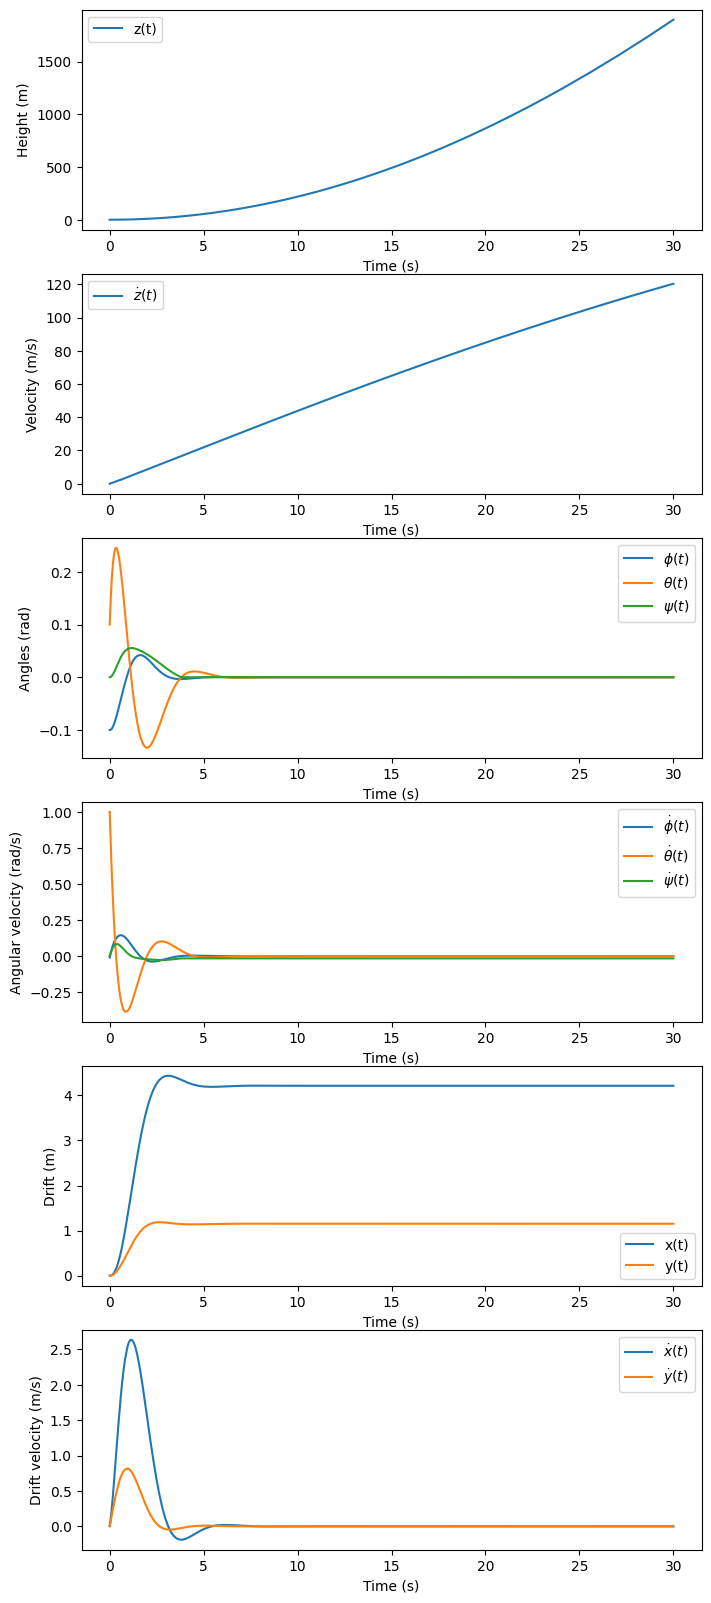

In [ ]:
#Plot the trajectory
fig, ax = plt.subplots(nrows=6, ncols=1,figsize=(8, 20))
labels = ['x(t)', 'y(t)', 'z(t)', r'$\dot{x}(t)$', r'$\dot{y}(t)$', r'$\dot{z}(t)$', r'$\phi(t)$', r'$\theta(t)$', r'$\psi(t)$', r'$\dot{\phi}(t)$', r'$\dot{\theta}(t)$', r'$\dot{\psi}(t)$']

ax[0].set_ylabel("Height (m)")
ax[0].plot(t_vals, State_vals[2], label = labels[2])

ax[1].set_ylabel("Velocity (m/s)")
ax[1].plot(t_vals, State_vals[5], label = labels[5])

ax[2].set_ylabel("Angles (rad)")
ax[2].plot(t_vals, State_vals[6], label = labels[6])
ax[2].plot(t_vals, State_vals[7], label = labels[7])
ax[2].plot(t_vals, State_vals[8], label = labels[8])

ax[3].set_ylabel("Angular velocity (rad/s)")
ax[3].plot(t_vals, State_vals[9], label = labels[9])
ax[3].plot(t_vals, State_vals[10], label = labels[10])
ax[3].plot(t_vals, State_vals[11], label = labels[11])

ax[4].set_ylabel("Drift (m)")
ax[4].plot(t_vals, State_vals[0], label = labels[0])
ax[4].plot(t_vals, State_vals[1], label = labels[1])

ax[5].set_ylabel("Drift velocity (m/s)")
ax[5].plot(t_vals, State_vals[3], label = labels[3])
ax[5].plot(t_vals, State_vals[4], label = labels[4])

for i in range(6):
    ax[i].set_xlabel("Time (s)")
    ax[i].legend()

#Print status (0=full run, 1=took too long, 2=crashed)
print(f"Status: {status}")
print(t_vals[-1])
#Show plots
plt.show()